# 04 — Probe R9 distribution before and after the η–R9 reweighting (maps without NF and with NF), passing probes

Created 2026-10-05. Class: deliverable.

**Purpose.** 1D distribution of the probe R9 of the **passing** probes, for the seeded and the unseeded leg, barrel (EB) and endcap (EE), three curves:
- **before**: selected probes, unweighted;
- **after, without NF**: the same probes weighted with `r9etaWeight_with_presel` of the old trees (map without NF);
- **after, with NF**: the same probes weighted with `r9etaWeight_with_presel` of the new trees (map with NF).

**Selection.** Exactly the probes of the normal-set fits: for each of the five fit categories the `cutBase` and `additionalCuts`
of its settings file, the |η| range of its binning, any $E_T$ bin, and 60 < m_ee < 120 GeV (as in notebook 01).
EB = the three EB categories together (R9 > 0.50), EE = the two EE categories together (R9 > 0.90): no probe of a region of the map
outside the fit categories (EB R9 < 0.50, EE R9 < 0.90, the EB–EE gap) is counted.
Histograms are filled for passing and failing probes (the pass flag of the settings file); only the passing ones are drawn.

**Inputs**
- Trees with NF: `fitter_inputs_2024_newPresel_20261001/fitter_input_2024_{Seed,Unseed}_SS.root`
- Trees without NF: `fitter_inputs_2024_HggOverDY/fitter_input_2024_{Seed,Unseed}_SS.root` (read in lockstep; only `r9etaWeight_with_presel` is taken from them)
- Settings: `settings_<category>_<leg>_HLT_2024_withPresel.py` (the files the fitter used)
- `data/cell_counts.npz` (notebook 01), for validation only

**Outputs**: `data/r9_before_after.npz`, `data/r9_before_after_summary.csv`, `plots/r9/r9_before_after_<leg>_<EB|EE>_pass.{pdf,png}`

```mermaid
flowchart LR
 A[A Config] --> B[B Parse settings]
 B --> C[C Scan trees: fill R9 histograms]
 C --> D[D Validate against notebook 01]
 D --> E[E Summary table]
 D --> F[F Plots]
 D --> G[G Save histograms]
```

Validation covers: per leg, category and pass/fail, the number of selected probes equals the count of notebook 01 exactly, and the
weighted yields equal notebook 01's count × map with NF and count × map without NF; the two trees are the same probes in the same
order (`event`, `probe_eta` equal in every chunk); no probe is selected by two categories; the R9 used by the cuts
(`ph_full5x5x_r9`) equals the R9 of the map lookup (`probe_full5x5_r9`) for every entry.
Not covered: the maps themselves, and anything the fit does with these probes.

Note on the lowest EE boundary: R9 is stored in single precision and the cut is `>= 0.90`; as in notebook 01 the cut value is
compared in single precision, so a probe whose stored R9 is the single-precision number closest to 0.90 (just below 0.90) is
selected. Such probes fall below the low edge of the EE axis; they are counted (`n_below_axis`) and not drawn.

## [A] Config
`uproot` reads ROOT trees without ROOT; `numpy` does the histogramming; `matplotlib` draws; `pandas` holds the summary table.

In [1]:
# [A] Config
from pathlib import Path
import re, time
import numpy as np
import pandas as pd
import uproot
import matplotlib.pyplot as plt

BASE     = Path('/home/santanu/Pictures/crab_2022_2023_2024')
TREES    = BASE / 'fitter_inputs_2024_newPresel_20261001'      # with NF
OLD_TREES = BASE / 'fitter_inputs_2024_HggOverDY'               # without NF
SETTINGS = Path('/home/santanu/Documents/Codex/2026-10-01/fin/outputs/lxplus_2024_newPresel_20261001')
STUDY    = Path('/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study')
DATA, PLOTS = STUDY / 'data', STUDY / 'plots' / 'r9'
PLOTS.mkdir(parents=True, exist_ok=True)
TREE     = 'PhotonToRECO/fitter_tree'
CATS     = ['EB_R9_0p50to0p55', 'EB_R9_0p55to0p85', 'EB_R9gt0p85', 'EE_R9_0p90to0p93', 'EE_R9gt0p93']
LEGS     = {'seed': 'Seed', 'unseed': 'Unseed'}
LEG_TEX  = {'seed': 'seeded', 'unseed': 'unseeded'}
REGIONS  = ['EB', 'EE']
MASS_WIN = (60.0, 120.0)
CHUNK    = 4_000_000
WEIGHT   = 'r9etaWeight_with_presel'
# histogram axis per region: (low edge, high edge, bin width); category boundaries drawn as dashed lines
AXIS     = {'EB': (0.50, 1.10, 0.005), 'EE': (0.50, 1.10, 0.005)}
BOUNDS   = {'EB': [0.55, 0.85], 'EE': [0.93]}
NBIN     = {r: int(round((hi - lo) / w)) for r, (lo, hi, w) in AXIS.items()}
EDGES    = {r: AXIS[r][0] + AXIS[r][2] * np.arange(NBIN[r] + 1) for r in REGIONS}
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.35, 'grid.linestyle': ':'})
print(NBIN)

{'EB': 120, 'EE': 120}


## [B] Parse settings
Same method as notebook 01: each settings file is executed with a stub `tnpSample`, so the cuts come from the files the fitter used.
`to_numpy_expr` turns the ROOT cut syntax into a numpy expression (every `&&` / `||` term gets parentheses).

In [2]:
# [B] Parse settings
def to_numpy_expr(s):
    return '(' + s.replace('&&', ') & (').replace('||', ') | (') + ')'

cfg = {}
for leg in LEGS:
    for cat in CATS:
        ns = {}
        src = (SETTINGS / f'settings_{cat}_{leg}_HLT_2024_withPresel.py').read_text()
        exec(src.replace('from libPython.tnpClassUtils import tnpSample', 'tnpSample = lambda *a, **k: k'), ns)
        add = set(ns['additionalCuts'].values()); assert len(add) == 1
        (flag,) = ns['flags'].values()
        cfg[(leg, cat)] = dict(cut=to_numpy_expr(ns['cutBase']) + ' & ' + to_numpy_expr(add.pop()), flag=to_numpy_expr(flag),
                               pt=np.array([b for b in ns['biningDef'] if b['var'] == 'ph_sc_et'][0]['bins']),
                               eta=np.array([b for b in ns['biningDef'] if b['var'] == 'ph_sc_abseta'][0]['bins']))
IDENT = set()
for c in cfg.values():
    IDENT |= set(re.findall(r'[A-Za-z_]\w*', c['cut'] + ' ' + c['flag'])) - {'abs'}
BRANCHES = sorted(IDENT | {'ph_sc_et', 'ph_sc_abseta', 'pair_mass', 'probe_full5x5_r9', 'ph_full5x5x_r9', 'event', 'probe_eta', WEIGHT})
print(len(cfg), 'settings parsed |', len(BRANCHES), 'branches')
print(('unseed', 'EE_R9gt0p93'), cfg[('unseed', 'EE_R9gt0p93')]['cut'], '| pass:', cfg[('unseed', 'EE_R9gt0p93')]['flag'])

10 settings parsed | 21 branches
('unseed', 'EE_R9gt0p93') (tag_Ele_pt > 35 ) & ( abs(tag_sc_eta) < 2.5 ) & ( tag_mva > -0.6 ) & ( probe_pt > 18 ) & ( ph_sc_abseta > 1.566 ) & ( ph_sc_abseta < 2.5 ) & ( probe_mva > -0.9 ) & ( probe_hoe < 0.08 ) & ( ph_full5x5x_r9 > 0.93 ) & ( probe_sieie < 0.032 ) & ( probe_phoIso_rhoCorr < 3.0 ) & ( probe_trkSumPtHollowConeDR03 < 6.0 ) & ( tag_seededPass == 1 ) & ( (ph_full5x5x_r9 > 0.8 ) | ( probe_pfRelIso03_chg_quad*probe_pt < 20 ) | ( probe_pfRelIso03_chg_quad < 0.3)) & (ph_full5x5x_r9 > 0.93) | pass: ((probe_passUnseed == 1))


## [C] Scan trees: fill R9 histograms
Per leg, category and pass/fail three histograms of `probe_full5x5_r9`: number of probes (before), sum of weights with NF and without NF (after).
The old tree is read in lockstep with the new one (`zip` of the two chunk iterators).
Bin 0 is the underflow, the last bin the overflow (R9 above the drawn range), so totals stay complete.
`np.bincount` counts how often each bin index occurs; with `weights=` it sums the weights per bin instead.

In [3]:
# [C] Scan trees
H_N = {k: np.zeros((2, NBIN[k[1][:2]] + 2)) for k in cfg}  # unweighted, [fail/pass, (under, bins..., over)]
H_W = {k: np.zeros((2, NBIN[k[1][:2]] + 2)) for k in cfg}  # sum of weights, map with NF
H_W0 = {k: np.zeros((2, NBIN[k[1][:2]] + 2)) for k in cfg} # sum of weights, map without NF
check = dict(entries={}, r9_branch_mismatch={}, double_selected={})
for leg, LEG in LEGS.items():
    t0 = time.time(); n = mis = dbl = 0
    new_it = uproot.open(TREES / f'fitter_input_2024_{LEG}_SS.root')[TREE].iterate(BRANCHES, step_size=CHUNK, library='np')
    old_it = uproot.open(OLD_TREES / f'fitter_input_2024_{LEG}_SS.root')[TREE].iterate([WEIGHT, 'event', 'probe_eta'], step_size=CHUNK, library='np')
    for a, o in zip(new_it, old_it):
        m = len(a['ph_sc_et']); n += m
        assert len(o['event']) == m and np.array_equal(o['event'], a['event']) and np.array_equal(o['probe_eta'], a['probe_eta']), 'trees not in lockstep'
        mis += int((a['ph_full5x5x_r9'] != a['probe_full5x5_r9']).sum())
        win = (a['pair_mass'] > MASS_WIN[0]) & (a['pair_mass'] < MASS_WIN[1])
        ns = dict(a); ns['abs'] = np.abs
        nsel = np.zeros(m, dtype=np.int8)
        for cat in CATS:
            c = cfg[(leg, cat)]; reg = cat[:2]; lo, hi, w = AXIS[reg]
            sel = eval(c['cut'], {}, ns) & win & (a['ph_sc_abseta'] >= c['eta'][0]) & (a['ph_sc_abseta'] < c['eta'][-1])
            sel &= (a['ph_sc_et'] >= c['pt'][0]) & (a['ph_sc_et'] < c['pt'][-1])
            nsel += sel
            ib = np.clip(np.digitize(a['probe_full5x5_r9'][sel], EDGES[reg]), 0, NBIN[reg] + 1)   # 0 = under, NBIN+1 = over
            ib += eval(c['flag'], {}, ns)[sel].astype(np.int64) * (NBIN[reg] + 2)                 # second half of the index = passing
            H_N[(leg, cat)] += np.bincount(ib, minlength=2 * (NBIN[reg] + 2)).reshape(2, -1)
            H_W[(leg, cat)] += np.bincount(ib, weights=a[WEIGHT][sel].astype(np.float64), minlength=2 * (NBIN[reg] + 2)).reshape(2, -1)
            H_W0[(leg, cat)] += np.bincount(ib, weights=o[WEIGHT][sel].astype(np.float64), minlength=2 * (NBIN[reg] + 2)).reshape(2, -1)
        dbl += int((nsel > 1).sum())
    check['entries'][leg] = n; check['r9_branch_mismatch'][leg] = mis; check['double_selected'][leg] = dbl
    print(f'{leg}: {n:,} entries, {time.time() - t0:.0f} s', flush=True)
print(check)

seed: 159,861,517 entries, 60 s


unseed: 159,861,517 entries, 60 s


{'entries': {'seed': 159861517, 'unseed': 159861517}, 'r9_branch_mismatch': {'seed': 0, 'unseed': 0}, 'double_selected': {'seed': 0, 'unseed': 0}}


## [D] Validate against notebook 01
Notebook 01 counted the same probes per map cell. Its totals per leg and category must be reproduced:
number of probes exactly, weighted yield = Σ cells N(cell) × map(cell), for the map with NF and the map without NF.

In [4]:
# [D] Validate
Z = np.load(DATA / 'cell_counts.npz')
MN, MO = Z['map_new'].ravel(), Z['map_old'].ravel()
rows = []
for (leg, cat), hn in H_N.items():
    cnt = Z[f'counts__{leg}__normal__{cat}'].sum(axis=0)               # [fail/pass, map cell], all ET bins
    for ip, probes in enumerate(('fail', 'pass')):
        n_ref, w_ref, w0_ref = int(cnt[ip].sum()), float((cnt[ip] * MN).sum()), float((cnt[ip] * MO).sum())
        n, w, w0 = int(hn[ip].sum()), float(H_W[(leg, cat)][ip].sum()), float(H_W0[(leg, cat)][ip].sum())
        assert n == n_ref, (leg, cat, probes, n, n_ref)
        assert abs(w / w_ref - 1) < 1e-5, (leg, cat, probes, w, w_ref)
        assert abs(w0 / w0_ref - 1) < 1e-5, (leg, cat, probes, w0, w0_ref)
        assert hn[ip, 0] < 1e-5 * n, (leg, cat, probes, hn[ip, 0])        # see the note on the lowest EE boundary
        rows.append(dict(leg=leg, cat=cat, region=cat[:2], probes=probes, n_unweighted=n, sum_weights=w, sum_weights_noNF=w0, rel_diff_to_nb01=w / w_ref - 1, rel_diff_noNF_to_nb01=w0 / w0_ref - 1,
                         n_below_axis=int(hn[ip, 0]), n_above_axis=int(hn[ip, -1]), w_above_axis=float(H_W[(leg, cat)][ip, -1]), w0_above_axis=float(H_W0[(leg, cat)][ip, -1])))
assert all(v == 0 for v in check['r9_branch_mismatch'].values()) and all(v == 0 for v in check['double_selected'].values())
assert check['entries'] == {'seed': 159861517, 'unseed': 159861517}
S = pd.DataFrame(rows)
print('probe counts equal notebook 01 exactly; weighted yields max |rel diff|:', f"{max(S.rel_diff_to_nb01.abs().max(), S.rel_diff_noNF_to_nb01.abs().max()):.1e}", '| probes below the axis:', int(S.n_below_axis.sum()))

probe counts equal notebook 01 exactly; weighted yields max |rel diff|: 1.1e-08 | probes below the axis: 0


## [E] Summary table
Per leg, category and probe set (all / pass / fail), and per leg and region: probes, sum of weights, their ratio, and what lies above the drawn R9 range.

In [5]:
# [E] Summary table
NUM = ['n_unweighted', 'sum_weights', 'sum_weights_noNF', 'n_below_axis', 'n_above_axis', 'w_above_axis', 'w0_above_axis']
A = S.groupby(['leg', 'cat', 'region'], as_index=False)[NUM].sum().assign(probes='all')      # pass + fail
S2 = pd.concat([S.drop(columns=['rel_diff_to_nb01', 'rel_diff_noNF_to_nb01']), A], ignore_index=True)
R = S2.groupby(['leg', 'region', 'probes'], as_index=False)[NUM].sum()                         # categories of one region together
R['cat'] = R.region + '_all_categories'
T = pd.concat([S2, R], ignore_index=True).sort_values(['leg', 'region', 'cat', 'probes']).reset_index(drop=True)
T['weighted_over_unweighted'] = T.sum_weights / T.n_unweighted
T['weighted_noNF_over_unweighted'] = T.sum_weights_noNF / T.n_unweighted
T['frac_n_above_axis'] = T.n_above_axis / T.n_unweighted
T['frac_w_above_axis'] = T.w_above_axis / T.sum_weights
T['frac_w0_above_axis'] = T.w0_above_axis / T.sum_weights_noNF
T.to_csv(DATA / 'r9_before_after_summary.csv', index=False, float_format='%.6g')
print(DATA / 'r9_before_after_summary.csv')
print(T[['leg', 'cat', 'probes', 'n_unweighted', 'sum_weights', 'weighted_noNF_over_unweighted', 'weighted_over_unweighted', 'n_below_axis', 'frac_n_above_axis', 'frac_w0_above_axis', 'frac_w_above_axis']].to_string(index=False))

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/r9_before_after_summary.csv
   leg               cat probes  n_unweighted  sum_weights  weighted_noNF_over_unweighted  weighted_over_unweighted  n_below_axis  frac_n_above_axis  frac_w0_above_axis  frac_w_above_axis
  seed  EB_R9_0p50to0p55    all        610203 6.011447e+05                       0.794398                  0.985155             0           0.000000            0.000000           0.000000
  seed  EB_R9_0p50to0p55   fail         65239 6.906920e+04                       0.830778                  1.058710             0           0.000000            0.000000           0.000000
  seed  EB_R9_0p50to0p55   pass        544964 5.320755e+05                       0.790043                  0.976350             0           0.000000            0.000000           0.000000
  seed  EB_R9_0p55to0p85    all      10623354 7.307250e+06                       0.613227                  0.687848             0       

## [F] Plots
One figure per leg and region, **passing probes only**. Upper pad: fraction of probes per bin, each curve normalised to its own total
(all selected probes of the region, including those outside the drawn range): unweighted, weighted with the map
without NF, weighted with the map with NF. Lower pad: each normalised weighted curve / normalised unweighted per bin. Dashed lines: boundaries of the fit categories.
`stairs` draws a histogram outline from bin contents and edges.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/r9/r9_before_after_seed_EB_pass.pdf


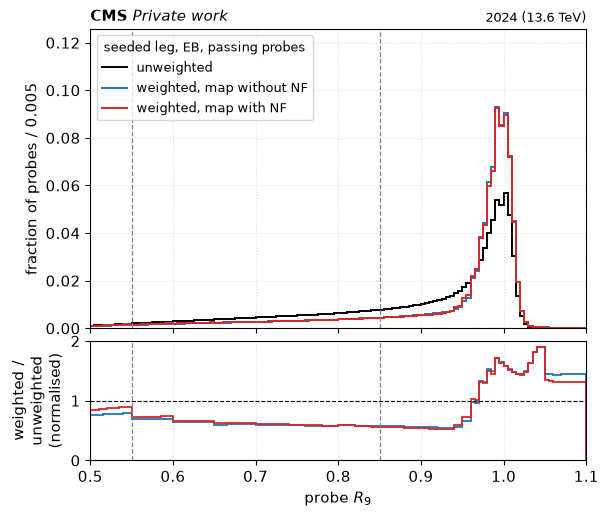

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/r9/r9_before_after_seed_EE_pass.pdf


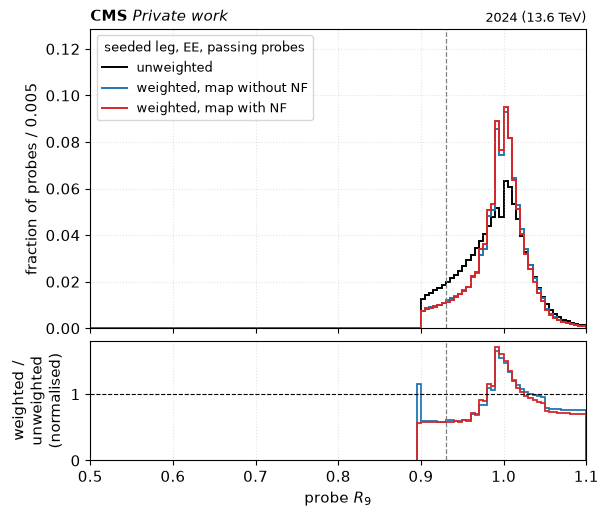

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/r9/r9_before_after_unseed_EB_pass.pdf


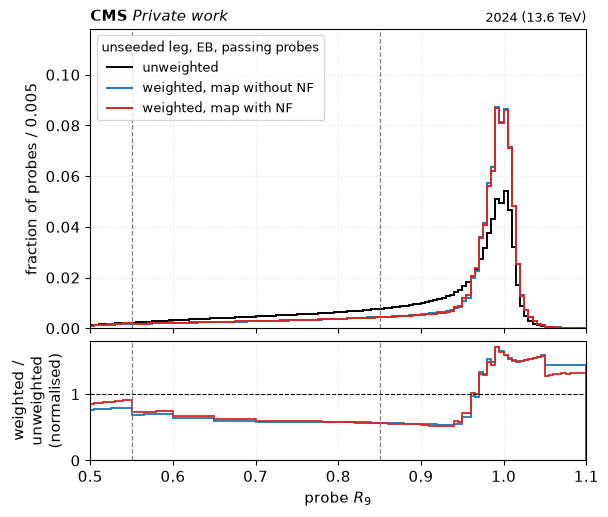

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/r9/r9_before_after_unseed_EE_pass.pdf


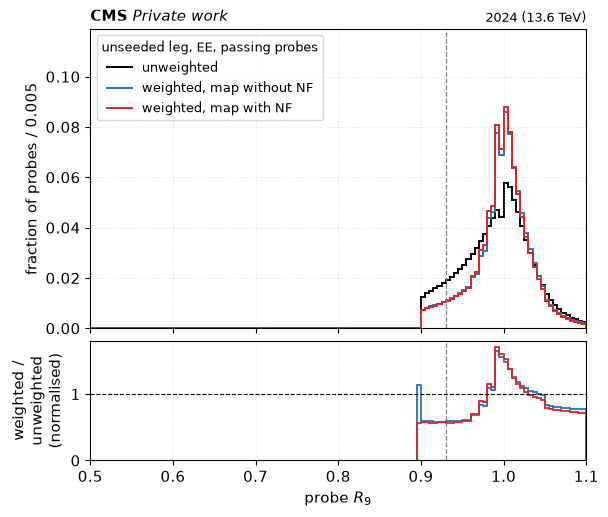

In [6]:
# [F] Plots
def label(ax, extra=''):
    ax.text(0.0, 1.015, r'$\bf{CMS}$ $\it{Private\ work}$', transform=ax.transAxes, fontsize=11, va='bottom')
    ax.text(1.0, 1.015, extra or '2024 (13.6 TeV)', transform=ax.transAxes, fontsize=9, va='bottom', ha='right')

def save(fig, path):
    for ext in ('pdf', 'png'):
        fig.savefig(path.with_suffix('.' + ext), dpi=150, bbox_inches='tight')
    print(path.with_suffix('.pdf'))

C_NO, C_NF = '#1f77b4', '#d62728'                           # without NF blue, with NF red (black = unweighted)
HR = {}                                                     # (leg, region) -> (unweighted, without NF, with NF), passing probes, drawn bins only
for leg in LEGS:
    for reg in REGIONS:
        cs = [c for c in CATS if c[:2] == reg]
        hn, h0, hw = (sum(H[(leg, c)][1] for c in cs) for H in (H_N, H_W0, H_W))            # row 1 = passing; with under/overflow
        hn, h0, hw = (h[1:-1] / h.sum() for h in (hn, h0, hw))                              # normalised to the total, drawn bins only
        HR[(leg, reg)] = (hn, h0, hw)
        fig, (a, b) = plt.subplots(2, 1, figsize=(6.4, 5.6), sharex=True, gridspec_kw={'height_ratios': [3, 1.2], 'hspace': 0.06})
        top = max(hn.max(), h0.max(), hw.max())
        sc = 1.0
        a.stairs(hn / sc, EDGES[reg], color='k', lw=1.4, label='unweighted')
        a.stairs(h0 / sc, EDGES[reg], color=C_NO, lw=1.4, label='weighted, map without NF')
        a.stairs(hw / sc, EDGES[reg], color=C_NF, lw=1.4, label='weighted, map with NF')
        with np.errstate(divide='ignore', invalid='ignore'):
            b.stairs(np.where(hn > 0, h0 / hn, np.nan), EDGES[reg], color=C_NO, lw=1.3)
            b.stairs(np.where(hn > 0, hw / hn, np.nan), EDGES[reg], color=C_NF, lw=1.3)
        b.axhline(1, color='k', lw=0.8, ls='--')
        for ax in (a, b):
            for x in BOUNDS[reg]:
                ax.axvline(x, color='gray', lw=0.9, ls='--')
        a.set_ylim(0, 1.35 * top / sc); a.set_xlim(EDGES[reg][0], EDGES[reg][-1])
        a.set_ylabel(f'fraction of probes / {AXIS[reg][2]:g}'); b.set_ylabel('weighted /\nunweighted\n(normalised)'); b.set_xlabel(r'probe $R_9$')
        a.legend(title=f'{LEG_TEX[leg]} leg, {reg}, passing probes', fontsize=9, title_fontsize=9, loc='upper left')
        label(a)
        save(fig, PLOTS / f'r9_before_after_{leg}_{reg}_pass')
        plt.show()

## [G] Save histograms
`np.savez` writes several arrays into one file, so the plots can be redrawn without scanning the trees again.

In [7]:
# [G] Save histograms
out = {f'edges__{r}': EDGES[r] for r in REGIONS}
for (leg, cat), hn in H_N.items():
    out[f'n__{leg}__{cat}'] = hn; out[f'w__{leg}__{cat}'] = H_W[(leg, cat)]; out[f'w0__{leg}__{cat}'] = H_W0[(leg, cat)]
np.savez(DATA / 'r9_before_after.npz', **out)
for (leg, reg), (hn, h0, hw) in HR.items():                 # the drawn histograms are sums of the saved per-category ones (passing row)
    cs = [c for c in CATS if c[:2] == reg]
    for h, key in ((hn, 'n'), (h0, 'w0'), (hw, 'w')):
        raw = sum(out[f'{key}__{leg}__{c}'][1] for c in cs); assert np.allclose(h, raw[1:-1] / raw.sum())
print(DATA / 'r9_before_after.npz', '| arrays:', len(out), '| per-category layout: [fail/pass, (underflow, bins..., overflow)]')

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/r9_before_after.npz | arrays: 32 | per-category layout: [fail/pass, (underflow, bins..., overflow)]
